#Food Delivery Time Prediction
Goal: given the details of an order — who is delivering it, how far it has to travel, the weather, the traffic, the time of day, and so on — predict how many minutes the delivery will take.

This is a supervised regression problem. The target, Time_taken(min), is a continuous number, and we have thousands of labelled historical orders to learn from.

Roadmap


Load & inspect the raw data


Clean the messy text and missing values


EDA — find which features actually move delivery time


Feature engineering — turn raw lat/long and timestamps into useful signals (distance, hour of day)


Encode & scale the features


Train and compare four models — Linear Regression → Decision Tree → Random Forest → XGBoost


Tune, evaluate, and save the best model for inference


The guiding question for every column is always the same: does this actually help predict delivery time?

In [180]:
# %pip install matplotlib seaborn
%pip install scikit-learn

In [181]:

# libraries: data handling, numeric ops, plotting
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [182]:
df = pd.read_csv('./Food delivery.csv')

In [183]:
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


In [184]:
df.shape

(45593, 20)

In [185]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  object 
 3   Delivery_person_Ratings      45593 non-null  object 
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  45593 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 
 13  Vehicle_conditio

In [186]:
type(df['Delivery_person_Age'][2])

str

In [187]:
df['Weatherconditions'].value_counts()

,count
Weatherconditions,
conditions Fog,7654
conditions Stormy,7586
conditions Cloudy,7536
conditions Sandstorms,7495
conditions Windy,7422
conditions Sunny,7284
conditions NaN,616


In [188]:
df[df['Weatherconditions'] == 'conditions NaN'].head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
74,0xa9f,BANGRES13DEL01,NaN,NaN,12.935662,77.614130,12.975662,77.654130,11-03-2022,NaN,15:30:00,conditions NaN,NaN,1,Drinks,scooter,0,No,Metropolitian,(min) 19
120,0x6e2,VADRES06DEL01,NaN,NaN,22.312790,73.170283,22.422790,73.280283,02-04-2022,NaN,18:25:00,conditions NaN,NaN,3,Snack,electric_scooter,0,No,Metropolitian,(min) 25
250,0x1b50,PUNERES16DEL01,NaN,NaN,18.536718,73.830327,18.646718,73.940327,08-03-2022,NaN,21:25:00,conditions NaN,NaN,3,Buffet,motorcycle,1,Yes,Urban,(min) 43
348,0x4c1,BANGRES13DEL02,NaN,NaN,12.935662,77.614130,13.065662,77.744130,02-03-2022,NaN,00:05:00,conditions NaN,NaN,3,Drinks,scooter,1,No,Metropolitian,(min) 26
425,0xc003,DEHRES13DEL02,NaN,NaN,-30.366322,-78.070453,30.496322,78.200453,18-02-2022,NaN,22:30:00,conditions NaN,NaN,3,Snack,scooter,1,No,Metropolitian,(min) 20


##Basic Data Cleaning and EDA



*   Fix free-text formatting quirks (e.g. "conditions Sunny" → "Sunny").
*   Replace the literal string 'NaN' with a real, pandas-recognized null.
*   Strip stray whitespace from every text column.

*   Convert numeric-looking text columns to actual numbers.
*   Impute missing values (median for skewed numerics, mode for categoricals).

In [189]:
df.columns

Index(['ID', 'Delivery_person_ID', 'Delivery_person_Age',
       'Delivery_person_Ratings', 'Restaurant_latitude',
       'Restaurant_longitude', 'Delivery_location_latitude',
       'Delivery_location_longitude', 'Order_Date', 'Time_Orderd',
       'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density',
       'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle',
       'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)'],
      dtype='object')

In [190]:
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


In [191]:
temp = 'conditions Sunny'

In [192]:
temp.split(' ')[1]

'Sunny'

In [193]:
df['Weatherconditions'] = df['Weatherconditions'].apply(lambda x: x.split(' ')[1] if not pd.isnull(x) else x)

In [194]:
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


In [195]:
df.select_dtypes('object').columns

Index(['ID', 'Delivery_person_ID', 'Delivery_person_Age',
       'Delivery_person_Ratings', 'Order_Date', 'Time_Orderd',
       'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density',
       'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival',
       'City', 'Time_taken(min)'],
      dtype='object')

In [196]:
# for col in df.select_dtypes('object').columns:
#   df[col] = df[col].str.split()
#   df[col] = df[col].replace('NaN', np.nan)

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].apply(
        lambda x: x[0] if isinstance(x, list) and len(x) == 1
        else " ".join(map(str, x)) if isinstance(x, list)
        else x
    )

In [197]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  object 
 3   Delivery_person_Ratings      45593 non-null  object 
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  45593 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 
 13  Vehicle_conditio

In [198]:
# df[df['Weatherconditions'].isnull()]
df[df['Weatherconditions'].isna()].head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)


In [199]:
for col in df.select_dtypes('object').columns:
  # df[col] = df[col].str.split()
  df[col] = df[col].str.strip()
  df[col] = df[col].replace(
    ['NaN', 'nan', ''],
    np.nan
)


In [200]:
df['Weatherconditions'].value_counts()

,count
Weatherconditions,
Fog,7654
Stormy,7586
Cloudy,7536
Sandstorms,7495
Windy,7422
Sunny,7284


In [201]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          43739 non-null  object 
 3   Delivery_person_Ratings      43685 non-null  object 
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  43862 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            44977 non-null  object 
 12  Road_traffic_density         44992 non-null  object 
 13  Vehicle_conditio

In [202]:
df['Festival'].value_counts()

,count
Festival,
No,44469
Yes,896


In [203]:
df['Festival'] = df['Festival'].replace(
    ['NaN', 'nan', ''],
    np.nan
)


In [204]:
print(df['Festival'].isna().sum())
print(df['Festival'].value_counts())

228
Festival
No     44469
Yes      896
Name: count, dtype: int64


In [205]:
df['Festival'].apply(repr).value_counts()

,count
Festival,
'No',44469
'Yes',896
nan,228


In [206]:
import numpy as np

df['Festival'] = df['Festival'].str.strip()

df['Festival'] = df['Festival'].replace(
    ['NaN', 'nan', ''],
    np.nan
)

In [207]:
print("Missing values:", df['Festival'].isna().sum())
print(df['Festival'].value_counts(dropna=False))

Missing values: 228
Festival
No     44469
Yes      896
NaN      228
Name: count, dtype: int64


In [208]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          43739 non-null  object 
 3   Delivery_person_Ratings      43685 non-null  object 
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  43862 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            44977 non-null  object 
 12  Road_traffic_density         44992 non-null  object 
 13  Vehicle_conditio

In [209]:
df.describe()

,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition
count,45593.000000,45593.000000,45593.000000,45593.000000,45593.000000
mean,17.017729,70.231332,17.465186,70.845702,1.023359
std,8.185109,22.883647,7.335122,21.118812,0.839065
min,-30.905562,-88.366217,0.010000,0.010000,0.000000
25%,12.933284,73.170000,12.988453,73.280000,0.000000
50%,18.546947,75.898497,18.633934,76.002574,1.000000
75%,22.728163,78.044095,22.785049,78.107044,2.000000
max,30.914057,88.433452,31.054057,88.563452,3.000000


In [210]:
df.columns

Index(['ID', 'Delivery_person_ID', 'Delivery_person_Age',
       'Delivery_person_Ratings', 'Restaurant_latitude',
       'Restaurant_longitude', 'Delivery_location_latitude',
       'Delivery_location_longitude', 'Order_Date', 'Time_Orderd',
       'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density',
       'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle',
       'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)'],
      dtype='object')

In [211]:
df.head()

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


In [212]:
type(df['Time_taken(min)'][0])

str

# Same one-value test for the target's "(min) 24" format
temp='(min) 24'


# Take the number after the space and cast to int
int(temp.split(" ")[1]) if pd.notnull(temp) else temp

24

In [213]:
# Target cleanup: "(min) 24" -> 24 (int). Keep real NaNs as NaN instead of crashing on them
df['Time_taken(min)']=df['Time_taken(min)'].apply(lambda temp :int(temp.split(" ")[1]) if pd.notnull(temp) else temp)

In [214]:
df['Time_taken(min)']

,Time_taken(min)
0,24
1,33
2,26
3,21
4,30
...,...
45588,32
45589,36
45590,16
45591,26


In [215]:
type(df['Time_taken(min)'][0])

numpy.int64

In [216]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          43739 non-null  object 
 3   Delivery_person_Ratings      43685 non-null  object 
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  43862 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            44977 non-null  object 
 12  Road_traffic_density         44992 non-null  object 
 13  Vehicle_conditio

In [217]:
# Looks numeric but may be stored as text — worth confirming before we cast
df['multiple_deliveries'].value_counts()

,count
multiple_deliveries,
1,28159
0,14095
2,1985
3,361


Cast the numeric-looking columns to real numbers. errors='coerce' is the key detail: anything that still cannot be parsed becomes NaN rather than raising an exception, which lets us impute those gaps in a single clean step later on.

In [218]:

# Force genuinely numeric columns to numeric dtype; errors='coerce' turns any
# leftover bad values into NaN instead of raising, so we can impute them next
for col in ['Delivery_person_Age','Delivery_person_Ratings','multiple_deliveries'] :
  df[col]=pd.to_numeric(df[col],errors='coerce')


In [219]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          43739 non-null  float64
 3   Delivery_person_Ratings      43685 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  43862 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            44977 non-null  object 
 12  Road_traffic_density         44992 non-null  object 
 13  Vehicle_conditio

In [220]:
# Summary stats — a quick way to spot impossible values (e.g. a rating > 5)
df.describe()

,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition,multiple_deliveries,Time_taken(min)
count,43739.000000,43685.000000,45593.000000,45593.000000,45593.000000,45593.000000,45593.000000,44600.000000,45593.000000
mean,29.567137,4.633780,17.017729,70.231332,17.465186,70.845702,1.023359,0.744664,26.294607
std,5.815155,0.334716,8.185109,22.883647,7.335122,21.118812,0.839065,0.572473,9.383806
min,15.000000,1.000000,-30.905562,-88.366217,0.010000,0.010000,0.000000,0.000000,10.000000
25%,25.000000,4.500000,12.933284,73.170000,12.988453,73.280000,0.000000,0.000000,19.000000
50%,30.000000,4.700000,18.546947,75.898497,18.633934,76.002574,1.000000,1.000000,26.000000
75%,35.000000,4.900000,22.728163,78.044095,22.785049,78.107044,2.000000,1.000000,32.000000
max,50.000000,6.000000,30.914057,88.433452,31.054057,88.563452,3.000000,3.000000,54.000000


In [221]:
df[df['Delivery_person_Ratings']>5]['Delivery_person_Ratings'].shape

(53,)

In [222]:
df['Delivery_person_Ratings'] = df['Delivery_person_Ratings'].clip(upper = 5)

In [223]:
df.describe()

,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Vehicle_condition,multiple_deliveries,Time_taken(min)
count,43739.000000,43685.000000,45593.000000,45593.000000,45593.000000,45593.000000,45593.000000,44600.000000,45593.000000
mean,29.567137,4.632567,17.017729,70.231332,17.465186,70.845702,1.023359,0.744664,26.294607
std,5.815155,0.331560,8.185109,22.883647,7.335122,21.118812,0.839065,0.572473,9.383806
min,15.000000,1.000000,-30.905562,-88.366217,0.010000,0.010000,0.000000,0.000000,10.000000
25%,25.000000,4.500000,12.933284,73.170000,12.988453,73.280000,0.000000,0.000000,19.000000
50%,30.000000,4.700000,18.546947,75.898497,18.633934,76.002574,1.000000,1.000000,26.000000
75%,35.000000,4.900000,22.728163,78.044095,22.785049,78.107044,2.000000,1.000000,32.000000
max,50.000000,5.000000,30.914057,88.433452,31.054057,88.563452,3.000000,3.000000,54.000000


In [224]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          43739 non-null  float64
 3   Delivery_person_Ratings      43685 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  43862 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            44977 non-null  object 
 12  Road_traffic_density         44992 non-null  object 
 13  Vehicle_conditio

In [225]:
df['Road_traffic_density'].value_counts()

,count
Road_traffic_density,
Low,15477
Jam,14143
Medium,10947
High,4425


In [226]:
df['Road_traffic_density'].mode()[0].strip()

'Low'

**Imputing the remaining missing values**


Two column types need two different strategies:


**Numeric columns** → fill with the median. The median is robust to outliers and skew, so a few extreme values will not drag the fill value around the way the mean would.


**Categorical columns** → fill with the mode (the most frequent category), which is the only sensible "average" for a non-numeric field.

In [227]:
# Numeric columns: fill missing values with the median (robust to outliers/skew)
for col in ['Delivery_person_Age','Delivery_person_Ratings','multiple_deliveries'] :
  df[col] = df[col].fillna(df[col].median())

In [228]:
# Categorical
for col in ['Weatherconditions','Road_traffic_density','Festival','City'] :
  df[col].fillna(df[col].mode()[0].strip(), inplace=True)

/tmp/ipykernel_663/1846979163.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[col].fillna(df[col].mode()[0].strip(), inplace=True)


In [229]:
df['Road_traffic_density'].value_counts()

,count
Road_traffic_density,
Low,16078
Jam,14143
Medium,10947
High,4425


In [230]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  float64
 3   Delivery_person_Ratings      45593 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  43862 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 
 13  Vehicle_conditio

3. Exploratory data analysis


Now the data is clean, we ask of every feature: what does its distribution look like, and does it actually relate to delivery time? For categorical features we compare the mean/median Time_taken(min) across groups; for numeric ones we look at trends.

In [231]:
df['Time_taken(min)'].describe()

,Time_taken(min)
count,45593.000000
mean,26.294607
std,9.383806
min,10.000000
25%,19.000000
50%,26.000000
75%,32.000000
max,54.000000


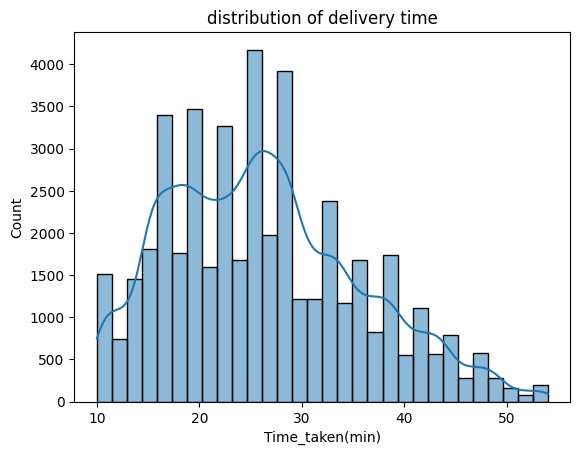

In [232]:

sns.histplot(df['Time_taken(min)'],bins=30,kde =True)
plt.title("distribution of delivery time")
plt.show()

In [233]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  float64
 3   Delivery_person_Ratings      45593 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  43862 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 
 13  Vehicle_conditio

In [234]:
df['Weatherconditions'].value_counts()

,count
Weatherconditions,
Fog,8270
Stormy,7586
Cloudy,7536
Sandstorms,7495
Windy,7422
Sunny,7284


In [235]:
import pandas as pd

categorical_cols = [
    'Weatherconditions',
    'Road_traffic_density',
    'Festival',
    'City'
]

for col in categorical_cols:
    # Convert text placeholders to actual missing values
    df[col] = df[col].replace('NaN', pd.NA)

    # Fill missing values with the mode
    df[col] = df[col].fillna(df[col].mode()[0])

In [236]:
df['Weatherconditions'].value_counts()

,count
Weatherconditions,
Fog,8270
Stormy,7586
Cloudy,7536
Sandstorms,7495
Windy,7422
Sunny,7284


In [237]:
print(df[categorical_cols].isna().sum())

Weatherconditions       0
Road_traffic_density    0
Festival                0
City                    0
dtype: int64


In [238]:
print("Actual missing values:", df['Weatherconditions'].isna().sum())

print("String 'NaN' values:",
      (df['Weatherconditions'] == 'NaN').sum())

print("String 'nan' values:",
      (df['Weatherconditions'] == 'nan').sum())

Actual missing values: 0
String 'NaN' values: 0
String 'nan' values: 0


In [239]:
df['Weatherconditions'].value_counts()

,count
Weatherconditions,
Fog,8270
Stormy,7586
Cloudy,7536
Sandstorms,7495
Windy,7422
Sunny,7284


In [240]:
# Weather vs delivery time
df.groupby('Weatherconditions')['Time_taken(min)'].agg(['count','mean','median','std'])

,count,mean,median,std
Weatherconditions,,,,
Cloudy,7536,28.917330,28.0,10.084352
Fog,8270,28.739541,28.0,10.100816
Sandstorms,7495,25.875517,26.0,8.618434
Stormy,7586,25.870815,26.0,8.473273
Sunny,7284,21.856947,20.0,8.327210
Windy,7422,26.118836,26.0,8.615702


In [241]:

df['Festival'].value_counts()

,count
Festival,
No,44697
Yes,896


In [242]:

df.groupby('Festival')['Time_taken(min)'].agg(['count','mean','median','std'])

,count,mean,median,std
Festival,,,,
No,44697,25.909256,25.0,9.052291
Yes,896,45.517857,45.0,4.001915


In [243]:
df['City'].value_counts()

,count
City,
Metropolitian,35293
Urban,10136
Semi-Urban,164


In [244]:

df.groupby('City')['Time_taken(min)'].agg(['count','mean','median','std'])

,count,mean,median,std
City,,,,
Metropolitian,35293,27.136486,26.0,9.205358
Semi-Urban,164,49.731707,49.0,2.693089
Urban,10136,22.984017,22.0,8.866011


In [245]:
df['Time_Orderd'].value_counts()

,count
Time_Orderd,
21:55:00,461
17:55:00,456
20:00:00,449
22:20:00,448
21:35:00,446
...,...
12:25:00,57
14:15:00,56
16:00:00,53


In [246]:

df.groupby('Time_Orderd')['Time_taken(min)'].agg(['count','mean','median','std'])

,count,mean,median,std
Time_Orderd,,,,
00:00:00,430,22.169767,21.0,7.201497
08:10:00,167,19.449102,19.0,5.717926
08:15:00,177,19.644068,19.0,5.511649
08:20:00,183,19.524590,19.0,5.564625
08:25:00,178,19.455056,18.0,6.137842
...,...,...,...,...
23:35:00,422,22.473934,22.0,7.197125
23:40:00,419,22.045346,21.0,7.316518
23:45:00,405,22.153086,21.0,7.450581


In [247]:
print("Actual missing:", df['Time_Orderd'].isna().sum())
print("String NaN:", df['Time_Orderd'].eq('NaN').sum())

Actual missing: 1731
String NaN: 0


In [248]:
import numpy as np

df['Time_Orderd'] = df['Time_Orderd'].replace(
    ['NaN', 'nan', 'None', ''],
    np.nan
)

print("Actual missing values:", df['Time_Orderd'].isna().sum())
print("String NaN values:", df['Time_Orderd'].eq('NaN').sum())

Actual missing values: 1731
String NaN values: 0


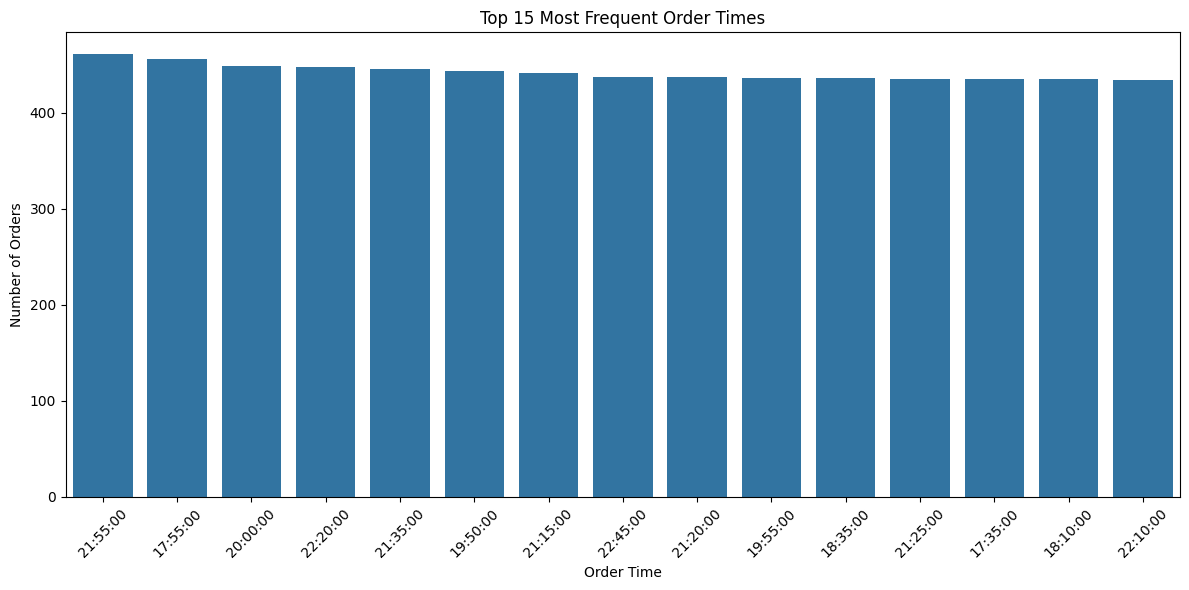

In [249]:

plt.figure(figsize=(12, 6))

top_times = df['Time_Orderd'].value_counts().head(15)

sns.barplot(x=top_times.index, y=top_times.values)

plt.title("Top 15 Most Frequent Order Times")
plt.xlabel("Order Time")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [250]:

df.groupby('Type_of_vehicle')['Time_taken(min)'].agg(['count','mean','median','std'])

,count,mean,median,std
Type_of_vehicle,,,,
bicycle,68,26.426471,26.0,9.262855
electric_scooter,3814,24.470110,24.0,8.610859
motorcycle,26435,27.605674,26.0,9.647811
scooter,15276,24.480754,24.0,8.704238


In [251]:

df.groupby('Type_of_order')['Time_taken(min)'].agg(['count','mean'])

,count,mean
Type_of_order,,
Buffet,11280,26.283511
Drinks,11322,26.187953
Meal,11458,26.419270
Snack,11533,26.286309


In [252]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  float64
 3   Delivery_person_Ratings      45593 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  43862 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 
 13  Vehicle_conditio

In [253]:
df['Delivery_person_Age'].describe()

,Delivery_person_Age
count,45593.000000
mean,29.584739
std,5.696333
min,15.000000
25%,25.000000
50%,30.000000
75%,34.000000
max,50.000000


<Axes: xlabel='Delivery_person_Age', ylabel='Count'>

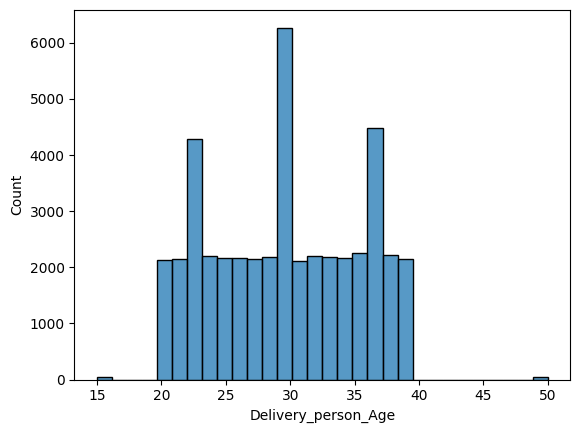

In [254]:
sns.histplot(df['Delivery_person_Age'], bins=30)

In [255]:
df[df['Delivery_person_Age']>40]['Delivery_person_Age'].shape

(53,)

Text(0, 0.5, 'Average Delivery Time (minutes)')

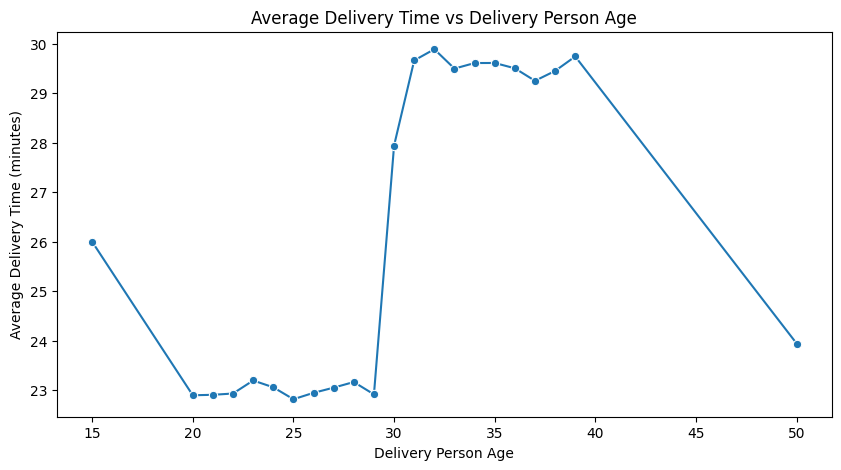

In [256]:
plt.figure(figsize=(10,5))

sns.lineplot(
    data = df,
    x="Delivery_person_Age",
    y="Time_taken(min)",
    estimator="mean",
    errorbar=None,
    marker="o"
)
plt.title("Average Delivery Time vs Delivery Person Age")
plt.xlabel("Delivery Person Age")
plt.ylabel("Average Delivery Time (minutes)")

In [257]:
df['Delivery_person_Ratings'].describe()

,Delivery_person_Ratings
count,45593.000000
mean,4.635389
std,0.324828
min,1.000000
25%,4.600000
50%,4.700000
75%,4.800000
max,5.000000


Text(0, 0.5, 'Average Delivery Time (minutes)')

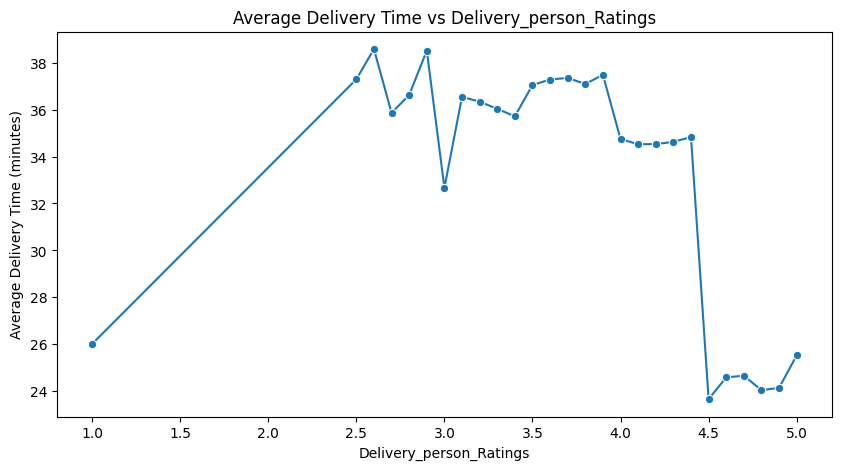

In [258]:
plt.figure(figsize=(10,5))

sns.lineplot(
    data = df,
    x="Delivery_person_Ratings",
    y="Time_taken(min)",
    estimator="mean",
    errorbar=None,
    marker="o"
)
plt.title("Average Delivery Time vs Delivery_person_Ratings")
plt.xlabel("Delivery_person_Ratings")
plt.ylabel("Average Delivery Time (minutes)")

In [259]:
# Share of deliveries by low-rated (<4) riders
df[df['Delivery_person_Ratings']<4].shape[0]/len(df)

# 2 % have ratings below than 4

0.02998267277871603

In [260]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  float64
 3   Delivery_person_Ratings      45593 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  43862 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 
 13  Vehicle_conditio

Text(0.5, 1.0, 'Correlation — numeric columns before feature engineering')

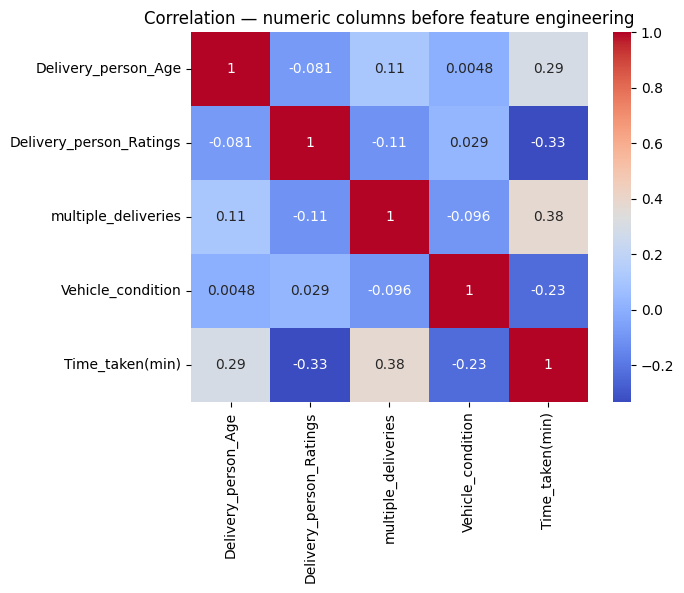

In [261]:
numeric_cols=['Delivery_person_Age','Delivery_person_Ratings','multiple_deliveries','Vehicle_condition','Time_taken(min)']

sns.heatmap(df[numeric_cols].corr(),annot=True,cmap='coolwarm')
plt.title('Correlation — numeric columns before feature engineering')
# plt.show()

jyada correlation toh nhi aaya hai

In [262]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  float64
 3   Delivery_person_Ratings      45593 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  43862 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 
 13  Vehicle_conditio

## 4. Feature engineering
Raw columns are not always model-ready. Two big opportunities here:


Location: we have restaurant and drop-off latitude/longitude — four raw numbers a model cannot use directly. What actually matters is the distance between them.


Time: the order timestamp hides a useful signal — the hour of day, which proxies for lunch/dinner rush.

In [263]:
df['Order_Date']

,Order_Date
0,19-03-2022
1,25-03-2022
2,19-03-2022
3,05-04-2022
4,26-03-2022
...,...
45588,24-03-2022
45589,16-02-2022
45590,11-03-2022
45591,07-03-2022


In [264]:
df['Time_Orderd']

,Time_Orderd
0,11:30:00
1,19:45:00
2,08:30:00
3,18:00:00
4,13:30:00
...,...
45588,11:35:00
45589,19:55:00
45590,23:50:00
45591,13:35:00


In [265]:
hour = pd.to_datetime(df['Time_Orderd'], format='%H:%M:%S', errors='coerce').dt.hour

In [266]:
hour.unique()

array([11., 19.,  8., 18., 13., 21., 17., 20., 14.,  9., 22., 12., 23.,
       nan, 10., 16., 15.,  0.])

In [267]:

# Does the hour of day relate to delivery time? (rush hours should stand out)
df.groupby(hour)['Time_taken(min)'].agg(['mean','median'])

,mean,median
Time_Orderd,,
0.0,22.169767,21.0
8.0,19.584158,19.0
9.0,19.543914,19.0
10.0,19.482170,19.0
11.0,26.380734,27.0
12.0,26.826233,27.0
13.0,27.538265,27.0
14.0,27.537295,27.0
15.0,23.194731,23.0


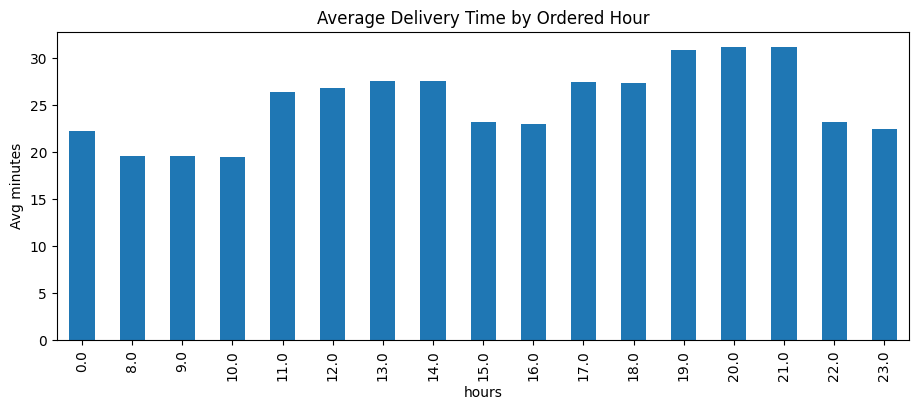

In [268]:
df.groupby(hour)['Time_taken(min)'].mean().plot(kind='bar', figsize=(11,4))
plt.title('Average Delivery Time by Ordered Hour')
plt.ylabel('Avg minutes')
plt.xlabel('hours')
plt.show()

In [269]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45593 entries, 0 to 45592
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45593 non-null  object 
 1   Delivery_person_ID           45593 non-null  object 
 2   Delivery_person_Age          45593 non-null  float64
 3   Delivery_person_Ratings      45593 non-null  float64
 4   Restaurant_latitude          45593 non-null  float64
 5   Restaurant_longitude         45593 non-null  float64
 6   Delivery_location_latitude   45593 non-null  float64
 7   Delivery_location_longitude  45593 non-null  float64
 8   Order_Date                   45593 non-null  object 
 9   Time_Orderd                  43862 non-null  object 
 10  Time_Order_picked            45593 non-null  object 
 11  Weatherconditions            45593 non-null  object 
 12  Road_traffic_density         45593 non-null  object 
 13  Vehicle_conditio

## Haversine Formula

The Haversine formula calculates the great-circle distance between two points on Earth's surface using their latitude and longitude coordinates.

### Step 1: Calculate the Haversine value

$$
a = \sin^2\left(\frac{\Delta \phi}{2}\right)
+ \cos(\phi_1)\cos(\phi_2)
\sin^2\left(\frac{\Delta \lambda}{2}\right)
$$

### Step 2: Calculate the central angle

$$
c = 2\arctan2\left(\sqrt{a}, \sqrt{1-a}\right)
$$

### Step 3: Calculate the distance

$$
\boxed{d = R \times c}
$$

### Parameters

- $\phi_1, \phi_2$: Latitudes of the two locations in radians.
- $\lambda_1, \lambda_2$: Longitudes of the two locations in radians.
- $\Delta \phi = \phi_2 - \phi_1$: Difference in latitude.
- $\Delta \lambda = \lambda_2 - \lambda_1$: Difference in longitude.
- $R$: Earth's mean radius, approximately **6,371 km**.
- $d$: Great-circle distance between the two locations in kilometers.

**Note:** Convert all latitude and longitude coordinates from degrees to radians before applying the formula.

In [270]:
def calculate_series_distance(
    lat1_series, lon1_series, lat2_series, lon2_series, miles=False
):
    """Calculates the great-circle (straight-line) distance between two series of

    lat/lon points using the Haversine formula. Returns distance in km (or
    miles). Turns four raw coordinate columns into one meaningful 'distance'
    feature.
    """
    r = 3956 if miles else 6371
    lat1, lon1, lat2, lon2 = map(
        np.radians, [lat1_series, lon1_series, lat2_series, lon2_series]
    )
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2) ** 2
    c = 2 * np.arcsin(np.sqrt(a))
    return c * r

In [271]:
df['distance_km']=calculate_series_distance(df['Restaurant_latitude'],df['Restaurant_longitude'],df['Delivery_location_latitude'],df['Delivery_location_longitude'])


In [272]:
df['distance_km'].describe()

,distance_km
count,45593.000000
mean,99.303911
std,1099.731281
min,1.465067
25%,4.663493
50%,9.264281
75%,13.763977
max,19692.674606


## Outlier check.


Some distance_km values are physically absurd (hundreds or thousands of km) — the tell-tale sign of corrupt 0,0 or swapped coordinates. We keep only realistic intra-city trips (< 100 km) so these bad rows do not distort the model.

In [273]:

# The >100 km rows: inspect the extreme distances (likely corrupt coordinates)
df[df['distance_km']>100]['distance_km'].describe()

,distance_km
count,431.000000
mean,9484.671093
std,6252.618252
min,2216.065794
25%,4434.856783
50%,5897.015762
75%,17132.390571
max,19692.674606


In [274]:

# The <100 km rows: inspect the extreme distances (likely corrupt coordinates)
df[df['distance_km']<100]['distance_km'].describe()

,distance_km
count,45162.000000
mean,9.735396
std,5.608508
min,1.465067
25%,4.663412
50%,9.220209
75%,13.681490
max,20.969489


In [275]:
df[df['distance_km']>100]

,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,...,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min),distance_km
92,0xc042,AGRRES010DEL01,34.0,4.7,-27.163303,78.057044,27.233303,78.127044,16-02-2022,23:00:00,...,Sandstorms,Low,1,Drinks,scooter,0.0,No,Metropolitian,15,6048.631240
283,0xc044,AGRRES12DEL03,32.0,4.7,-27.165108,78.015053,27.225108,78.075053,13-02-2022,20:55:00,...,Sandstorms,Jam,2,Meal,scooter,1.0,No,Metropolitian,31,6047.919478
289,0x4db,PUNERES02DEL03,30.0,4.7,-18.551440,-73.804855,18.611440,73.864855,05-03-2022,NaN,...,Stormy,Jam,2,Meal,scooter,0.0,No,Urban,12,16612.239055
425,0xc003,DEHRES13DEL02,30.0,4.7,-30.366322,-78.070453,30.496322,78.200453,18-02-2022,NaN,...,Fog,Low,3,Snack,scooter,1.0,No,Metropolitian,20,17744.205087
534,0x473,MYSRES07DEL03,30.0,4.7,-12.325461,-76.632278,12.385461,76.692278,03-03-2022,NaN,...,Fog,Low,3,Buffet,scooter,1.0,No,Metropolitian,16,17118.828366
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
44933,0xc0c2,AURGRES03DEL03,30.0,4.9,-19.874733,75.353942,19.904733,75.383942,15-02-2022,22:20:00,...,Fog,Low,1,Buffet,motorcycle,0.0,No,Metropolitian,15,4423.276011
45020,0x56b,PUNERES04DEL01,30.0,4.7,-18.514210,73.838429,18.524210,73.848429,21-03-2022,NaN,...,Fog,Low,3,Drinks,electric_scooter,1.0,No,Metropolitian,30,4118.484540
45108,0xc01b,GOARES18DEL01,30.0,4.7,-15.493950,-73.827423,15.563950,73.897423,16-02-2022,NaN,...,Windy,Jam,2,Meal,scooter,1.0,No,Urban,19,16560.629487
45182,0xc0c7,KNPRES16DEL02,30.0,4.0,-26.482581,80.315628,26.532581,80.365628,17-02-2022,22:25:00,...,Sandstorms,Low,0,Drinks,motorcycle,1.0,No,Metropolitian,34,5895.019482


In [276]:

df=df[df['distance_km']<100].reset_index(drop=True)

In [277]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45162 entries, 0 to 45161
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45162 non-null  object 
 1   Delivery_person_ID           45162 non-null  object 
 2   Delivery_person_Age          45162 non-null  float64
 3   Delivery_person_Ratings      45162 non-null  float64
 4   Restaurant_latitude          45162 non-null  float64
 5   Restaurant_longitude         45162 non-null  float64
 6   Delivery_location_latitude   45162 non-null  float64
 7   Delivery_location_longitude  45162 non-null  float64
 8   Order_Date                   45162 non-null  object 
 9   Time_Orderd                  43706 non-null  object 
 10  Time_Order_picked            45162 non-null  object 
 11  Weatherconditions            45162 non-null  object 
 12  Road_traffic_density         45162 non-null  object 
 13  Vehicle_conditio

In [278]:
df['order_hour'] = pd.to_datetime(df['Time_Orderd'], format='%H:%M:%S', errors='coerce').dt.hour

In [279]:
# A handful of unparseable timestamps become NaN hours — fill with the median hour
df['order_hour'].fillna(df['order_hour'].median(),inplace=True)

/tmp/ipykernel_663/1417926182.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['order_hour'].fillna(df['order_hour'].median(),inplace=True)


In [280]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45162 entries, 0 to 45161
Data columns (total 22 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           45162 non-null  object 
 1   Delivery_person_ID           45162 non-null  object 
 2   Delivery_person_Age          45162 non-null  float64
 3   Delivery_person_Ratings      45162 non-null  float64
 4   Restaurant_latitude          45162 non-null  float64
 5   Restaurant_longitude         45162 non-null  float64
 6   Delivery_location_latitude   45162 non-null  float64
 7   Delivery_location_longitude  45162 non-null  float64
 8   Order_Date                   45162 non-null  object 
 9   Time_Orderd                  43706 non-null  object 
 10  Time_Order_picked            45162 non-null  object 
 11  Weatherconditions            45162 non-null  object 
 12  Road_traffic_density         45162 non-null  object 
 13  Vehicle_conditio

In [281]:
# Too many unique delivery-person IDs to one-hot encode — so we won't use the ID as a feature
len(df['Delivery_person_ID'].unique())

1320

## 5. Assemble the feature matrix X and target y


We pick the columns that carry real predictive signal. Note what we drop: the raw lat/long (now summarised by distance_km), the raw timestamps (now order_hour), and identifiers like Delivery_person_ID — an ID is a label, not a feature, and one-hot encoding thousands of unique IDs would just invite overfitting.

In [282]:
features=['Delivery_person_Age','Delivery_person_Ratings','distance_km','order_hour','Weatherconditions','Road_traffic_density',
          'Vehicle_condition','Type_of_order','Type_of_vehicle','multiple_deliveries','Festival','City']


In [283]:
X = df[features]

In [284]:
X.shape

(45162, 12)

In [285]:
y = df['Time_taken(min)']

## 6. Encoding categorical variables


Categorical features come in two flavours, and each needs different treatment:


Ordinal (has a natural order): Road_traffic_density runs Low < Medium < High < Jam. We map it to 0, 1, 2, 3 so the model can learn a single "more traffic → more time" trend.
Nominal (no order): weather, city, vehicle type, order type. These get one-hot encoded into 0/1 columns. drop_first=True removes one redundant column per feature to avoid the dummy-variable trap (perfect multicollinearity).

In [286]:
# Traffic density has a real order (Low < Medium < High < Jam) -> ordinal encode instead of one-hot,
# so the model can learn a single, sensible increasing relationship
traffic_mapping={
    'Low':0,
    'Medium': 1,
    'High' : 2,
    'Jam' : 3
}

X['Road_traffic_density']=X['Road_traffic_density'].map(traffic_mapping)

/tmp/ipykernel_663/2671883894.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['Road_traffic_density']=X['Road_traffic_density'].map(traffic_mapping)


In [287]:

X['Road_traffic_density']

,Road_traffic_density
0,2
1,3
2,0
3,1
4,2
...,...
45157,2
45158,3
45159,0
45160,2


In [288]:
X['Weatherconditions'].value_counts()

,count
Weatherconditions,
Fog,8071
Stormy,7544
Cloudy,7485
Sandstorms,7442
Windy,7382
Sunny,7238


In [289]:
X = pd.get_dummies(X, columns=['Type_of_order','Type_of_vehicle','Festival','City','Weatherconditions'],drop_first=True,dtype=int)

In [290]:
X.shape

(45162, 21)

In [291]:
X['order_hour'].isna().sum()

np.int64(0)

In [292]:
X['order_hour'] = X['order_hour'].fillna(X['order_hour'].median())

## 7. Train / test split


We hold out 20% of the data that the model never sees during training. Evaluating on this untouched set is the only honest way to estimate how the model will perform on new, real orders. random_state=42 makes the split reproducible.

## Train/test split


Hold out 20% of the data the model never trains on, so we can honestly check how well it generalizes.

In [293]:
from sklearn.model_selection import train_test_split


In [294]:

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [295]:
# Confirm the split sizes (~80% train / ~20% test)
X_train.shape,X_test.shape

((36129, 21), (9033, 21))

## 8. Feature scaling (standardization)
Each feature is rescaled to mean 0 and standard deviation 1:


This matters for Linear Regression, whose coefficients otherwise get distorted by features on wildly different scales (e.g. distance_km vs a 0/1 dummy). Tree-based models (Decision Tree, Random Forest, XGBoost) are scale-invariant and do not need it — but scaling does them no harm, so we apply one consistent transform for every model.


### Formula

$$
z = \frac{x - \mu}{\sigma}
$$

Where:
- $x$ = Original feature value
- $\mu$ = Mean of the feature
- $\sigma$ = Standard deviation of the feature
- $z$ = Standardized value


Critical: the scaler is fit on the training set only, then applied to the test set. Fitting on the test set would leak information about the held-out data and inflate our scores.

## Feature scaling


Standardize all features to mean 0 / std 1. Needed for Linear Regression (distance-based math); tree-based models don't need it, but scaling doesn't hurt them either, so we apply it once for all models.

In [296]:
from sklearn.preprocessing import StandardScaler
scaler= StandardScaler()

In [297]:
# from sklearn.impute import SimpleImputer
# imputer = SimpleImputer(strategy="median")

In [298]:
#Fit the scaler on TRAIN ONLY, then apply it to both — never fit on test data
X_train_scaled=scaler.fit_transform(X_train)

X_test_scaled=scaler.transform(X_test)

In [299]:
# imputer = SimpleImputer(strategy="median")

# X_train_scaled = imputer.fit_transform(X_train)
# X_test_scaled = imputer.transform(X_test)

In [300]:
# Note: scaling returns a plain numpy array — column names and index are lost here
X_train_scaled

array([[-1.33517305,  0.51156709, -0.35171278, ..., -0.44643354,
        -0.43645196,  2.26789395],
       [ 1.12628719,  0.19877778,  1.34683601, ..., -0.44643354,
        -0.43645196, -0.44093773],
       [-0.80771728, -0.42680083,  1.30714108, ...,  2.23997508,
        -0.43645196, -0.44093773],
       ...,
       [ 1.65374296, -0.11401152, -0.67284161, ..., -0.44643354,
        -0.43645196,  2.26789395],
       [ 0.77465001,  0.51156709, -1.18141457, ..., -0.44643354,
        -0.43645196, -0.44093773],
       [ 0.77465001, -1.36516875,  0.65355565, ..., -0.44643354,
        -0.43645196, -0.44093773]])

In [301]:
# Put back into DataFrames with the original column names/index for readability
X_train_scaled=pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index,)
X_test_scaled=pd.DataFrame(X_test_scaled,columns=X_test.columns,index=X_test.index)

In [302]:
import joblib
# Save the fitted scaler
joblib.dump(scaler, "standard_scaler.pkl")

['standard_scaler.pkl']

## Model 1 — Linear Regression (baseline)


Simplest possible model: fits one straight-line relationship across all features. Fast and interpretable

In [303]:
from sklearn.linear_model import LinearRegression

In [304]:
lr=LinearRegression()


lr.fit(X_train_scaled,y_train)

LinearRegression()

In a Jupyter environment, please rerun this cell to show the HTML representation or trust the notebook.


On GitHub, the HTML representation is unable to render, please try loading this page with nbviewer.org.

In [305]:
print("NaN values in X_train_scaled:",
      np.isnan(X_train_scaled).sum())

print("NaN values in y_train:",
      np.isnan(y_train).sum())

NaN values in X_train_scaled: Delivery_person_Age                 0
Delivery_person_Ratings             0
distance_km                         0
order_hour                          0
Road_traffic_density                0
Vehicle_condition                   0
multiple_deliveries                 0
Type_of_order_Drinks                0
Type_of_order_Meal                  0
Type_of_order_Snack                 0
Type_of_vehicle_electric_scooter    0
Type_of_vehicle_motorcycle          0
Type_of_vehicle_scooter             0
Festival_Yes                        0
City_Semi-Urban                     0
City_Urban                          0
Weatherconditions_Fog               0
Weatherconditions_Sandstorms        0
Weatherconditions_Stormy            0
Weatherconditions_Sunny             0
Weatherconditions_Windy             0
dtype: int64
NaN values in y_train: 0


In [306]:
X['order_hour'].isna().sum()

np.int64(0)

In [307]:
X['order_hour'] = X['order_hour'].fillna(
    X['order_hour'].median()
)

In [308]:
X['order_hour'].isna().sum()

np.int64(0)

The linear model
Linear regression predicts with one weight per feature plus an intercept:



The equation of a linear regression model is:

$$
\hat{y} = \theta_0 + \theta_1 x_1 + \theta_2 x_2 + \cdots + \theta_n x_n
$$

Where:
- $\hat{y}$ = Predicted output
- $\theta_0$ = Intercept (bias)
- $\theta_1, \theta_2, \ldots, \theta_n$ = Model coefficients (weights)
- $x_1, x_2, \ldots, x_n$ = Input features
- $n$ = Number of input features

In vector notation:

$$
\hat{y} = \boldsymbol{\theta}^{T}\mathbf{x}
$$

The model learns the optimal coefficients by minimizing the Mean Squared Error (MSE):

$$
MSE = \frac{1}{m}\sum_{i=1}^{m}(y_i-\hat{y}_i)^2
$$

Where $m$ is the number of training examples.



Training finds the weights
 that minimise the sum of squared errors. It is fast and fully interpretable — the perfect baseline for the tree models to beat.

In [309]:
# One coefficient per feature (in the scaled space) — larger magnitude = bigger influence
lr.coef_


array([ 2.25707747, -2.17742371,  2.08640083, -0.54457378,  2.92036387,
       -1.7354634 ,  1.71928013, -0.07066725, -0.02591592, -0.01696524,
       -0.4410398 , -0.97325398, -1.21548077,  1.33110365,  0.58436762,
       -0.80964671,  0.08306582, -1.00542433, -1.01075931, -2.31276779,
       -0.96904815])

In [310]:
# Line the coefficients up with their feature names to read off which features matter most
X_train.columns

Index(['Delivery_person_Age', 'Delivery_person_Ratings', 'distance_km',
       'order_hour', 'Road_traffic_density', 'Vehicle_condition',
       'multiple_deliveries', 'Type_of_order_Drinks', 'Type_of_order_Meal',
       'Type_of_order_Snack', 'Type_of_vehicle_electric_scooter',
       'Type_of_vehicle_motorcycle', 'Type_of_vehicle_scooter', 'Festival_Yes',
       'City_Semi-Urban', 'City_Urban', 'Weatherconditions_Fog',
       'Weatherconditions_Sandstorms', 'Weatherconditions_Stormy',
       'Weatherconditions_Sunny', 'Weatherconditions_Windy'],
      dtype='object')

### How We Evaluate: RMSE and R²


**1. Root Mean Squared Error (RMSE)**


RMSE measures the typical magnitude of prediction errors in the target's original units (minutes).

$$
RMSE = \sqrt{\frac{1}{m}\sum_{i=1}^{m}(y_i-\hat{y}_i)^2}
$$

Where:
- \(m\) = Number of observations
- \(y_i\) = Actual delivery time
- \(\hat{y}_i\) = Predicted delivery time

**Interpretation:** If RMSE \(\approx 4\), the prediction errors have a typical magnitude of roughly 4 minutes. Lower RMSE indicates better predictive accuracy.

**2. R² (Coefficient of Determination)**

R² measures how much of the variation in the target variable is explained by the model.

$$
R^2 = 1-\frac{\sum_{i=1}^{m}(y_i-\hat{y}_i)^2}{\sum_{i=1}^{m}(y_i-\bar{y})^2}
$$

Where:
- \(y_i\) = Actual delivery time
- \(\hat{y}_i\) = Predicted delivery time
- \(\bar{y}\) = Mean of actual delivery times

**Interpretation:**
- \(R^2 = 1\): Perfect predictions.
- \(R^2 = 0\): The model performs as well as predicting the mean of the actual target values, on the evaluated dataset.
- \(R^2 < 0\): The model performs worse than that mean-baseline predictor.

**3. Train vs. Test Evaluation**

We calculate both metrics on the training and test datasets to assess generalization.

- **Good generalization:** Similar train and test performance.
- **Overfitting:** Excellent training performance but substantially worse test performance.
- **Underfitting:** Poor performance on both training and test datasets.

A lower RMSE and an R² closer to 1 generally indicate a better model, but both metrics should be interpreted together and compared on the same dataset.

In [311]:
from sklearn.metrics import r2_score,mean_squared_error

In [312]:
y_pred_test = lr.predict(X_test_scaled)

In [313]:
y_pred_test

array([35.54696752, 25.18681408, 32.53582321, ..., 25.47312622,
       28.86950385, 41.39609062])

In [314]:
rmse_train = np.sqrt(mean_squared_error(y_train, lr.predict(X_train_scaled)))

In [315]:
# Test RMSE (average error in minutes)
rmse_test=np.sqrt(mean_squared_error(y_test,y_pred_test))

In [316]:
rmse_train

np.float64(6.043532429197743)

In [317]:

r2_test=r2_score(y_test,y_pred_test)

In [318]:

r2_train=r2_score(y_train,lr.predict(X_train_scaled))

In [319]:
# Train: RMSE, R²
print(rmse_train,r2_train)


6.043532429197743 0.5833426978406996


In [320]:
# Test: RMSE, R²  — close to train, so the linear model underfits rather than overfits
print(rmse_test,r2_test)

6.212510956097219 0.569315466760959


In [321]:
# r2 test result is bad -> moderate performance

# Model 2 — Decision Tree


Splits the data with a series of yes/no questions on features ("is traffic Jam?", "is distance > 5km?") to separate slow orders from fast ones. Powerful, but an unconstrained tree will memorize the training data.

In [322]:
from sklearn.tree import DecisionTreeRegressor

dt = DecisionTreeRegressor(random_state = 42)

dt.fit(X_train_scaled, y_train)

DecisionTreeRegressor(random_state=42)

In [323]:
y_pred_dt=dt.predict(X_test_scaled)

In [324]:
# Test performance
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error

mse=mean_squared_error(y_test,dt.predict(X_test_scaled))
rmse=np.sqrt(mse)

r2=r2_score(y_test,dt.predict(X_test_scaled))

print("dt rmse",rmse)
print("dt r2",r2)

dt rmse 5.463261556519014
dt r2 0.6669350543728361


In [325]:
# Now check TRAIN performance for comparison — this is how we catch overfitting
mse=mean_squared_error(y_train,dt.predict(X_train_scaled))
rmse=np.sqrt(mse)

r2=r2_score(y_train,dt.predict(X_train_scaled))

print("dt rmse",rmse)
print("dt r2",r2)

dt rmse 0.0
dt r2 1.0


# Model 3 — Random Forest


Hundreds of decision trees, each trained on a random subset of rows and features, with predictions averaged. Individual trees' errors tend to cancel out, which is why forests overfit far less than a single deep tree.

In [326]:
from sklearn.ensemble import RandomForestRegressor

rf=RandomForestRegressor(n_estimators=100,random_state=42)

rf.fit(X_train_scaled,y_train)

RandomForestRegressor(random_state=42)

In [327]:
# Test performance
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error

mse=mean_squared_error(y_test,rf.predict(X_test_scaled))
rmse=np.sqrt(mse)

r2=r2_score(y_test,rf.predict(X_test_scaled))

print("rf rmse",rmse)
print("rf r2",r2)

rf rmse 4.028540060127521
rf r2 0.8188992229800744


In [328]:
# Now check TRAIN performance for comparison — this is how we catch overfitting
mse=mean_squared_error(y_train,rf.predict(X_train_scaled))
rmse=np.sqrt(mse)

r2=r2_score(y_train,rf.predict(X_train_scaled))

print("rf rmse",rmse)
print("rf r2",r2)

rf rmse 1.5065961890052253
rf r2 0.9741064847794211


# Hyperparameter tuning with RandomizedSearchCV


A full grid search over tree count × depth × leaf size × feature fraction is combinatorially huge. RandomizedSearchCV instead samples a fixed number of random combinations and cross-validates each — far cheaper, and in practice it lands very close to the grid-search optimum. (Left commented out so the notebook re-runs quickly; uncomment to reproduce.)

Tuning: randomized search over tree count/depth/features — cheaper than a full grid search over this many hyperparameters.

In [329]:
# from sklearn.model_selection import RandomizedSearchCV

# rf_param_dist={
#     'n_estimators':[200,300,400,500],
#     'max_depth':[10,15,20,25,None],
#     'min_samples_leaf':[1,2,4],
#     'min_samples_split':[2,5,10],
#     'max_features':['sqrt','log2',0.5]
# }
# # Sample 25 random combinations instead of testing every combination exhaustively
# rf_search=RandomizedSearchCV(RandomForestRegressor(random_state=42),rf_param_dist,n_iter=25,cv=3,scoring='r2',random_state=42,n_jobs=-1)
# rf_search.fit(X_train_scaled,y_train)

# print("best params",rf_search.best_params_)
# rf_best=rf_search.best_estimator_

In [330]:

from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor

rf_param_dist = {
    'n_estimators': [50, 100],
    'max_depth': [10, 15, None],
    'min_samples_leaf': [1, 2],
    'min_samples_split': [2, 5],
    'max_features': ['sqrt', 0.5]
}

rf_search = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=1),
    rf_param_dist,
    n_iter=3,
    cv=2,
    scoring='r2',
    random_state=42,
    n_jobs=-1,
    verbose=2
)

rf_search.fit(X_train, y_train)

print("Best params:", rf_search.best_params_)
rf_best = rf_search.best_estimator_


Fitting 2 folds for each of 3 candidates, totalling 6 fits
Best params: {'n_estimators': 100, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 15}


In [331]:
r2_rf_tuned=r2_score(y_test,rf_best.predict(X_test_scaled))

rmse_rf_tuned=np.sqrt(mean_squared_error(y_test,rf_best.predict(X_test_scaled)))

print("tuned rf rmse",rmse_rf_tuned)
print("tuned rf r2",r2_rf_tuned)

tuned rf rmse 9.153508322294638
tuned rf r2 0.06502477771351745


In [332]:
# this not showing much more difference

# Model 4 — XGBoost


Trees trained sequentially — each new tree specifically corrects the errors of all trees before it (gradient boosting). Usually the strongest single model for structured/tabular data like ours.

In [333]:
from xgboost import XGBRegressor


xgb=XGBRegressor(n_estimators=100,random_state=42)


xgb.fit(X_train_scaled,y_train)


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=None, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=100,
             n_jobs=None, num_parallel_tree=None, ...)

In [334]:
from sklearn.metrics import r2_score,mean_absolute_error,mean_squared_error
mse=mean_squared_error(y_test,xgb.predict(X_test_scaled))
rmse=np.sqrt(mse)
r2=r2_score(y_test,xgb.predict(X_test_scaled))
print("xgb rmse",rmse)
print("xgb r2",r2)

xgb rmse 3.998954397870163
xgb r2 0.8215494751930237


In [335]:

xgb_param_dist = {
    'n_estimators': [50, 100],
    'max_depth': [3, 5],
    'learning_rate': [0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0],
    'reg_alpha': [0, 0.1],
    'reg_lambda': [1, 2]
}

xgb_search = RandomizedSearchCV(
    XGBRegressor(
        random_state=42,
        n_jobs=1
    ),
    xgb_param_dist,
    n_iter=3,
    cv=2,
    scoring='r2',
    random_state=42,
    n_jobs=-1,
    verbose=2
)

xgb_search.fit(X_train_scaled, y_train)

print("Best params:", xgb_search.best_params_)
xgb_best = xgb_search.best_estimator_


Fitting 2 folds for each of 3 candidates, totalling 6 fits
Best params: {'subsample': 1.0, 'reg_lambda': 2, 'reg_alpha': 0.1, 'n_estimators': 50, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.8}


In [336]:
r2_xgb_train=r2_score(y_train,xgb_best.predict(X_train_scaled))
rmse_xgb_train=np.sqrt(mean_squared_error(y_train,xgb_best.predict(X_train_scaled)))
print("xgb train rmse",rmse_xgb_train)
print("xgb train r2",r2_xgb_train)

xgb train rmse 4.331490540533867
xgb train r2 0.7859712839126587


In [337]:
r2_xgb_test=r2_score(y_test,xgb_best.predict(X_test_scaled))
rmse_xgb_test=np.sqrt(mean_squared_error(y_test,xgb_best.predict(X_test_scaled)))
print("xgb rmse",rmse_xgb_test)
print("xgb r2",r2_xgb_test)

xgb rmse 4.399490691098738
xgb r2 0.784011960029602


In [338]:
# Number of features p — needed for the adjusted R² formula below
X_test_scaled.shape[1]

21

### Adjusted $R^2$ — a fairer score when comparing feature sets

Plain $R^2$ has a flaw: it **never decreases** when you add a feature, even a useless one. That makes it useless for deciding whether a *new* feature actually earns its place. Adjusted $R^2$ fixes this by penalising the number of features $p$:

$$R^2_{\text{adj}} = 1 - (1 - R^2)\frac{n - 1}{n - p - 1}$$

where $n$ is the number of samples and $p$ the number of features. It only rises if a new feature helps *more than* the complexity it adds — exactly the yardstick we need for the experiment in the next section.

In [339]:
# Test Adjusted R²
y_test_pred = xgb_best.predict(X_test_scaled)

n_test = len(y_test)
p_test = X_test_scaled.shape[1]

adj_r2_xgb_test = 1 - (1 - r2_xgb_test) * (n_test - 1) / (n_test - p_test - 1)

print("xgb test adjusted r2", adj_r2_xgb_test)

xgb test adjusted r2 0.7835086031503014


# Feature experiment: does "order period" help?

Hypothesis: delivery time spikes during meal rushes, so bucketing order_hour into Lunch / Dinner / Normal might add signal beyond the raw hour.

We test this honestly:

Build the new feature on the unscaled train/test data (so the buckets are correct).
One-hot encode it and fit a fresh scaler on train only.
Retrain our strongest model with the same tuned hyperparameters, changing only the feature set — a fair, controlled comparison.
We then read Adjusted R² (from above) to judge whether the extra feature was worth it.

In [340]:
# Recall: X_train is the UNSCALED training features — we build the new feature here first
X_train

,Delivery_person_Age,Delivery_person_Ratings,distance_km,order_hour,Road_traffic_density,Vehicle_condition,multiple_deliveries,Type_of_order_Drinks,Type_of_order_Meal,Type_of_order_Snack,...,Type_of_vehicle_motorcycle,Type_of_vehicle_scooter,Festival_Yes,City_Semi-Urban,City_Urban,Weatherconditions_Fog,Weatherconditions_Sandstorms,Weatherconditions_Stormy,Weatherconditions_Sunny,Weatherconditions_Windy
24844,22.0,4.8,7.762944,17.0,1,2,1.0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
33010,36.0,4.7,17.297866,21.0,3,2,2.0,1,0,0,...,0,1,1,0,0,0,0,0,0,0
16599,25.0,4.5,17.075035,21.0,3,2,0.0,0,0,0,...,1,0,0,0,0,0,0,1,0,0
35248,38.0,4.8,3.040816,11.0,2,1,0.0,0,1,0,...,0,1,0,0,0,0,0,1,0,0
14293,26.0,5.0,3.145067,8.0,0,0,1.0,0,0,0,...,1,0,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11284,38.0,4.9,4.657592,21.0,3,0,1.0,0,0,1,...,1,0,0,0,0,0,0,0,0,1
44732,30.0,4.7,20.181187,23.0,0,0,0.0,0,0,1,...,1,0,0,0,0,0,0,0,0,1
38158,39.0,4.6,5.960265,13.0,2,2,1.0,1,0,0,...,1,0,0,0,0,0,0,0,0,1
860,34.0,4.8,3.105356,8.0,0,1,1.0,0,0,1,...,0,1,0,0,0,1,0,0,0,0


In [341]:
# Bucket the order hour into meal periods (lunch / dinner rushes vs the rest)
def order_period(hour):
  if 12<=hour<=14 :
    return "Lunch"
  elif 19<=hour<=21 :
    return "Dinner"
  else :
    return "Normal"

In [342]:
# 1. Copy unscaled data
X_train_exp = X_train.copy()
X_test_exp = X_test.copy()

In [343]:
# 2. Create the new feature BEFORE scaling
X_train_exp['order_period'] = X_train_exp['order_hour'].apply(order_period)
X_test_exp['order_period'] = X_test_exp['order_hour'].apply(order_period)

In [344]:
# Confirm the new order_period column landed correctly
X_train_exp

,Delivery_person_Age,Delivery_person_Ratings,distance_km,order_hour,Road_traffic_density,Vehicle_condition,multiple_deliveries,Type_of_order_Drinks,Type_of_order_Meal,Type_of_order_Snack,...,Type_of_vehicle_scooter,Festival_Yes,City_Semi-Urban,City_Urban,Weatherconditions_Fog,Weatherconditions_Sandstorms,Weatherconditions_Stormy,Weatherconditions_Sunny,Weatherconditions_Windy,order_period
24844,22.0,4.8,7.762944,17.0,1,2,1.0,0,0,0,...,0,0,0,0,0,0,0,0,1,Normal
33010,36.0,4.7,17.297866,21.0,3,2,2.0,1,0,0,...,1,1,0,0,0,0,0,0,0,Dinner
16599,25.0,4.5,17.075035,21.0,3,2,0.0,0,0,0,...,0,0,0,0,0,0,1,0,0,Dinner
35248,38.0,4.8,3.040816,11.0,2,1,0.0,0,1,0,...,1,0,0,0,0,0,1,0,0,Normal
14293,26.0,5.0,3.145067,8.0,0,0,1.0,0,0,0,...,0,0,0,0,1,0,0,0,0,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11284,38.0,4.9,4.657592,21.0,3,0,1.0,0,0,1,...,0,0,0,0,0,0,0,0,1,Dinner
44732,30.0,4.7,20.181187,23.0,0,0,0.0,0,0,1,...,0,0,0,0,0,0,0,0,1,Normal
38158,39.0,4.6,5.960265,13.0,2,2,1.0,1,0,0,...,0,0,0,0,0,0,0,0,1,Lunch
860,34.0,4.8,3.105356,8.0,0,1,1.0,0,0,1,...,1,0,0,0,1,0,0,0,0,Normal


In [345]:
# 3. One-hot encode
X_train_exp = pd.get_dummies(
    X_train_exp, columns=['order_period'], drop_first=True, dtype=int
)

X_test_exp = pd.get_dummies(
    X_test_exp, columns=['order_period'], drop_first=True, dtype=int
)

In [346]:
# 4. Create a NEW scaler and fit ONLY on expanded training data
scaler_exp = StandardScaler()

X_train_exp_scaled = scaler_exp.fit_transform(X_train_exp)
X_test_exp_scaled = scaler_exp.transform(X_test_exp)

In [347]:
# Retrain our strongest model (same tuned hyperparameters) WITH the new feature, for a fair comparison
xgb_with_period = XGBRegressor(**xgb_search.best_params_, random_state=42)
xgb_with_period.fit(X_train_exp_scaled, y_train)

XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.8, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=5,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=50,
             n_jobs=None, num_parallel_tree=None, ...)

In [348]:
n_test = X_test_exp.shape[0]
p_test = X_test_exp.shape[1]
r2_with_period_test = r2_score(y_test, xgb_with_period.predict(X_test_exp_scaled))
adj_r2_test = 1 - (1 - r2_with_period_test) * (n_test - 1) / (n_test - p_test - 1)
print("Test Adjusted R²:", adj_r2_test)

Test Adjusted R²: 0.7863465571776653


In [349]:
X_train_exp.columns

Index(['Delivery_person_Age', 'Delivery_person_Ratings', 'distance_km',
       'order_hour', 'Road_traffic_density', 'Vehicle_condition',
       'multiple_deliveries', 'Type_of_order_Drinks', 'Type_of_order_Meal',
       'Type_of_order_Snack', 'Type_of_vehicle_electric_scooter',
       'Type_of_vehicle_motorcycle', 'Type_of_vehicle_scooter', 'Festival_Yes',
       'City_Semi-Urban', 'City_Urban', 'Weatherconditions_Fog',
       'Weatherconditions_Sandstorms', 'Weatherconditions_Stormy',
       'Weatherconditions_Sunny', 'Weatherconditions_Windy',
       'order_period_Lunch', 'order_period_Normal'],
      dtype='object')

In [350]:
X_train_exp.columns.tolist()

['Delivery_person_Age',
 'Delivery_person_Ratings',
 'distance_km',
 'order_hour',
 'Road_traffic_density',
 'Vehicle_condition',
 'multiple_deliveries',
 'Type_of_order_Drinks',
 'Type_of_order_Meal',
 'Type_of_order_Snack',
 'Type_of_vehicle_electric_scooter',
 'Type_of_vehicle_motorcycle',
 'Type_of_vehicle_scooter',
 'Festival_Yes',
 'City_Semi-Urban',
 'City_Urban',
 'Weatherconditions_Fog',
 'Weatherconditions_Sandstorms',
 'Weatherconditions_Stormy',
 'Weatherconditions_Sunny',
 'Weatherconditions_Windy',
 'order_period_Lunch',
 'order_period_Normal']

### Fixing One-Hot Encoding and Checking Categories
Since we used `drop_first=True` on `order_period` (which contains `['Dinner', 'Lunch', 'Normal']`), the alphabetically first category `Dinner` was dropped as the baseline reference.

Let's re-run the encoding with `drop_first=False` to preserve all three categories explicitly so the XGBoost model can learn split conditions directly on `Dinner`.

In [351]:
# 1. Copy fresh unscaled data
X_train_exp = X_train.copy()
X_test_exp = X_test.copy()

# 2. Re-create order_period
X_train_exp['order_period'] = X_train_exp['order_hour'].apply(order_period)
X_test_exp['order_period'] = X_test_exp['order_hour'].apply(order_period)

# 3. One-hot encode WITHOUT dropping the first category
X_train_exp = pd.get_dummies(
    X_train_exp, columns=['order_period'], drop_first=False, dtype=int
)
X_test_exp = pd.get_dummies(
    X_test_exp, columns=['order_period'], drop_first=False, dtype=int
)

# 4. Fit fresh scaler on the expanded dataset
scaler_exp = StandardScaler()
X_train_exp_scaled = scaler_exp.fit_transform(X_train_exp)
X_test_exp_scaled = scaler_exp.transform(X_test_exp)

# 5. Retrain our tuned XGBoost model and verify adjusted R²
xgb_with_period = XGBRegressor(**xgb_search.best_params_, random_state=42)
xgb_with_period.fit(X_train_exp_scaled, y_train)

n_test = X_test_exp.shape[0]
p_test = X_test_exp.shape[1]

r2_with_period_test = r2_score(y_test, xgb_with_period.predict(X_test_exp_scaled))
adj_r2_test = 1 - (1 - r2_with_period_test) * (n_test - 1) / (n_test - p_test - 1)

print("New Columns added:", [col for col in X_train_exp.columns if 'order_period' in col])
print("New Test Adjusted R²:", adj_r2_test)

New Columns added: ['order_period_Dinner', 'order_period_Lunch', 'order_period_Normal']
New Test Adjusted R²: 0.7846888465208016


#Results & model persistence
XGBoost (tuned) is our best model. Below we save both the fitted model and the scaler with joblib, then reload them and run a few sample predictions — the same two-step (scaler.transform → model.predict) any production service would use.

The order_period experiment left Adjusted R² essentially decreased (~0.784), so we keep the simpler model — a useful reminder that not every engineered feature earns its keep.

In [352]:
joblib.dump(xgb_best, "xgb_best.pkl")

['xgb_best.pkl']

In [353]:
model = joblib.load("/content/xgb_best.pkl")
scaler = joblib.load("/content/standard_scaler.pkl")


In [354]:

# Grab 3 raw (unscaled) test rows to mimic new incoming orders
sample=X_test[0:3]

In [355]:
# Fit the loaded scaler on training data to compute mean and std, then transform the sample
# scaler.fit(X_train)
sample_scaled = scaler.transform(sample)
sample_scaled

array([[ 1.65374296, -0.11401152,  0.22631349, -0.0970367 , -0.2941108 ,
        -1.22287855,  0.44096304, -0.57614642, -0.57738223, -0.581942  ,
        -0.30332399,  0.85172799, -0.70975062, -0.14046011, -0.06009336,
        -0.53440835, -0.46657758, -0.4455861 , -0.44643354, -0.43645196,
        -0.44093773],
       [ 1.47792437,  0.82435639, -1.46506334, -1.57096294, -1.09715863,
        -0.02337324,  0.44096304,  1.73566989, -0.57738223, -0.581942  ,
        -0.30332399, -1.17408376,  1.40894558, -0.14046011, -0.06009336,
        -0.53440835, -0.46657758, -0.4455861 , -0.44643354, -0.43645196,
        -0.44093773],
       [-1.33517305, -1.05237944,  1.26748879,  0.53464598,  1.31198488,
         1.17613207,  0.44096304, -0.57614642,  1.73195493, -0.581942  ,
        -0.30332399, -1.17408376,  1.40894558, -0.14046011, -0.06009336,
        -0.53440835, -0.46657758, -0.4455861 , -0.44643354, -0.43645196,
        -0.44093773]])

In [356]:
# Predict delivery time (minutes) for the 3 samples
predictions=model.predict(sample_scaled)

In [357]:
# Model's predicted minutes
predictions

array([37.36372 , 20.636496, 37.8142  ], dtype=float32)

In [358]:
# Actual minutes — compare against the predictions above
y_test[0:3].values

array([46, 19, 40])

In [359]:
hasattr(scaler, "mean_")   # False means it was never fitted

True

In [360]:
X_train.columns


Index(['Delivery_person_Age', 'Delivery_person_Ratings', 'distance_km',
       'order_hour', 'Road_traffic_density', 'Vehicle_condition',
       'multiple_deliveries', 'Type_of_order_Drinks', 'Type_of_order_Meal',
       'Type_of_order_Snack', 'Type_of_vehicle_electric_scooter',
       'Type_of_vehicle_motorcycle', 'Type_of_vehicle_scooter', 'Festival_Yes',
       'City_Semi-Urban', 'City_Urban', 'Weatherconditions_Fog',
       'Weatherconditions_Sandstorms', 'Weatherconditions_Stormy',
       'Weatherconditions_Sunny', 'Weatherconditions_Windy'],
      dtype='object')

In [361]:
import joblib
import pandas as pd

cols = [
    'Delivery_person_Age', 'Delivery_person_Ratings', 'distance_km',
    'order_hour', 'Road_traffic_density', 'Vehicle_condition',
    'multiple_deliveries', 'Type_of_order_Drinks', 'Type_of_order_Meal',
    'Type_of_order_Snack', 'Type_of_vehicle_electric_scooter',
    'Type_of_vehicle_motorcycle', 'Type_of_vehicle_scooter', 'Festival_Yes',
    'City_Semi-Urban', 'City_Urban', 'Weatherconditions_Fog',
    'Weatherconditions_Sandstorms', 'Weatherconditions_Stormy',
    'Weatherconditions_Sunny', 'Weatherconditions_Windy',
]

row = {c: 0 for c in cols}
row.update({
    'Delivery_person_Age': 39, 'Delivery_person_Ratings': 4.6,
    'distance_km': 11.007735, 'order_hour': 17,
    'Road_traffic_density': 1, 'Vehicle_condition': 0,
    'multiple_deliveries': 1, 'Type_of_vehicle_motorcycle': 1,
})
df = pd.DataFrame([row])[cols]

scaler = joblib.load('standard_scaler.pkl')
model = joblib.load('xgb_best.pkl')

scaled = scaler.transform(df)
print("scaled:", scaled[0][:7].round(4))
print("prediction:", model.predict(scaled)[0])

scaled: [ 1.6537 -0.114   0.2263 -0.097  -0.2941 -1.2229  0.441 ]
prediction: 37.36372


In [362]:
print(type(model))   # check: XGBRegressor?

model.save_model("xgb_best.json")

<class 'xgboost.sklearn.XGBRegressor'>
